# Учёт банковских операций: объектная модель

Ноутбук демонстрирует модель расчётного и сберегательного счетов с
историей операций, валидацией, аналитикой, переводами и загрузкой
«грязных» данных из CSV/JSON. Вся логика вынесена в пакет bank,
ноутбук только импортирует его и показывает поведение.

**Структура проекта**

```
python_5/
├── bank_accounts.ipynb        # демонстрация (этот ноутбук)
├── requirements.txt
├── transactions_dirty.csv     # исходные «грязные» данные
├── transactions_dirty.json
└── bank/                      # пакет с моделью
    ├── __init__.py            # публичный API пакета
    ├── constants.py           # типы операций, статусы, источники
    ├── transaction.py         # Transaction — запись истории
    ├── validation.py          # имя (regex), суммы, время операции
    ├── analytics.py           # крупные операции, график, пересчёт
    ├── accounts/
    │   ├── base.py            # BankAccount — общая логика учёта
    │   ├── checking.py        # CheckingAccount — расчётный счёт
    │   └── savings.py         # SavingsAccount — сберегательный счёт
    └── data_import/
        ├── readers.py         # чтение CSV/JSON, разбор дат
        ├── cleaning.py        # правила отбраковки строк
        └── report.py          # ImportReport — отчёт об отбраковке
```

Все бизнес-правила описаны один раз в BankAccount (единый метод
_apply, через который проходит любое изменение баланса); наследники
только переопределяют «точки расширения» (allowed_operations, _withdraw_denial_reason).

In [1]:
from datetime import datetime, timedelta

import pandas as pd

from bank import (INTEREST, CheckingAccount, SavingsAccount,
                  recalculate_balance)

---
# Задание 1. Счёт с историей операций

### Этап 1: операции и история

In [2]:
start = datetime(2025, 10, 1, 10, 0)

account = CheckingAccount("Иван Петров", 1000)
print(account)

account.deposit(500, timestamp=start)
account.deposit(2500, timestamp=start + timedelta(days=1, hours=3))
account.withdraw(700, timestamp=start + timedelta(days=2))
account.withdraw(1200, timestamp=start + timedelta(days=3, hours=5))

# Неуспешная попытка: средств недостаточно
failed = account.withdraw(10_000, timestamp=start + timedelta(days=4))
print("Попытка снять 10 000:", failed.status, "-", failed.reason)

account.deposit(300, timestamp=start + timedelta(days=5))
account.withdraw(1500, timestamp=start + timedelta(days=6))

print("\nТекущий баланс:", account.balance)
account.print_history()

Расчётный счёт ACC-1000 | Иван Петров | баланс 1000.00
Попытка снять 10 000: fail - недостаточно средств

Текущий баланс: 900.0
История ACC-1000 (Иван Петров), записей: 7
  2025-10-01 10:00:00 | deposit  |     500.00 | баланс    1500.00 | success
  2025-10-02 13:00:00 | deposit  |    2500.00 | баланс    4000.00 | success
  2025-10-03 10:00:00 | withdraw |     700.00 | баланс    3300.00 | success
  2025-10-04 15:00:00 | withdraw |    1200.00 | баланс    2100.00 | success
  2025-10-05 10:00:00 | withdraw |   10000.00 | баланс    2100.00 | fail | недостаточно средств
  2025-10-06 10:00:00 | deposit  |     300.00 | баланс    2400.00 | success
  2025-10-07 10:00:00 | withdraw |    1500.00 | баланс     900.00 | success


История в табличном виде:

In [3]:
account.history_df()[["timestamp", "operation", "amount",
                      "balance_after", "status", "reason"]]

,timestamp,operation,amount,balance_after,status,reason
0,2025-10-01 10:00:00,deposit,500.0,1500.0,success,
1,2025-10-02 13:00:00,deposit,2500.0,4000.0,success,
2,2025-10-03 10:00:00,withdraw,700.0,3300.0,success,
3,2025-10-04 15:00:00,withdraw,1200.0,2100.0,success,
4,2025-10-05 10:00:00,withdraw,10000.0,2100.0,fail,недостаточно средств
5,2025-10-06 10:00:00,deposit,300.0,2400.0,success,
6,2025-10-07 10:00:00,withdraw,1500.0,900.0,success,


Номера счетов уникальны — счётчик общий для всех типов счетов:

In [4]:
other_accounts = [CheckingAccount("Anna Smith"),
                  SavingsAccount("Олег Сидоров", 100),
                  CheckingAccount("John Brown")]
for acc in [account] + other_accounts:
    print(acc.number, acc.account_type, acc.owner)

numbers = [acc.number for acc in [account] + other_accounts]
print("Все номера уникальны:", len(numbers) == len(set(numbers)))

ACC-1000 checking Иван Петров
ACC-1001 checking Anna Smith
ACC-1002 savings Олег Сидоров
ACC-1003 checking John Brown
Все номера уникальны: True


### Этап 2: график изменения баланса

Данные берутся из истории через history_df(). Неуспешная попытка
тоже видна на графике: баланс в этой точке не меняется.

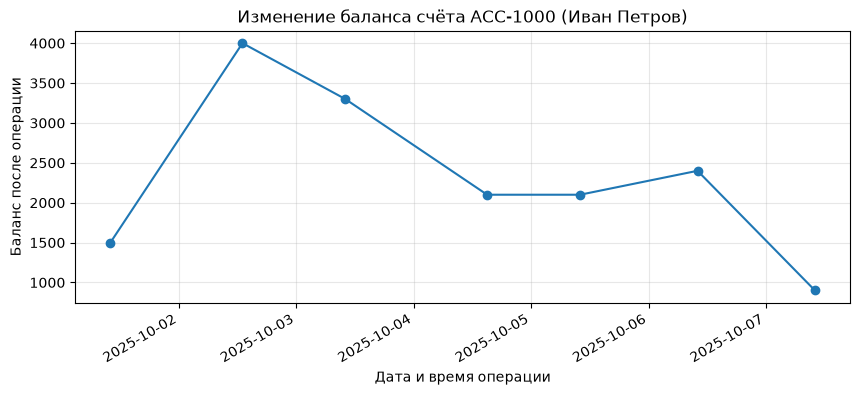

In [5]:
account.plot_balance()

---
# Задание 2. Разные типы счетов и аналитика

In [6]:
checking = CheckingAccount("Мария Иванова", 5000)
savings = SavingsAccount("Peter Parker", 10_000)

for acc in (checking, savings):
    print(acc, "| тип:", acc.account_type, "|", repr(acc))

Расчётный счёт ACC-1004 | Мария Иванова | баланс 5000.00 | тип: checking | CheckingAccount(number='ACC-1004', owner='Мария Иванова', balance=5000.0)
Сберегательный счёт ACC-1005 | Peter Parker | баланс 10000.00 | тип: savings | SavingsAccount(number='ACC-1005', owner='Peter Parker', balance=10000.0)


### Начисление процентов на сберегательном счёте (7 %)

In [7]:
transaction = savings.add_interest(7)
print(transaction)
print("Баланс после начисления:", savings.balance)

2026-10-23 16:43:14 | interest |     700.00 | баланс   10700.00 | success
Баланс после начисления: 10700.0


### Отклонение снятия сверх 50 % баланса

In [8]:
print("Баланс:", savings.balance, "| лимит снятия:", savings.balance * 0.5)

denied = savings.withdraw(6000)          # больше 50 % — отказ
print(denied)
print("Баланс не изменился:", savings.balance)

allowed = savings.withdraw(5000)         # не больше 50 % — успех
print(allowed)

# На расчётном счёте такого ограничения нет
print(checking.withdraw(4000))

Баланс: 10700.0 | лимит снятия: 5350.0
2026-10-23 16:43:14 | withdraw |    6000.00 | баланс   10700.00 | fail | превышен лимит снятия 50% баланса
Баланс не изменился: 10700.0
2026-10-23 16:43:14 | withdraw |    5000.00 | баланс    5700.00 | success
2026-10-23 16:43:14 | withdraw |    4000.00 | баланс    1000.00 | success


### Выборка последних N крупных успешных операций

In [9]:
for amount in (1500, 200, 3000, 50, 2500, 800, 4000):
    checking.deposit(amount)
checking.withdraw(100_000)               # крупная, но неуспешная

checking.print_history()
print("\nПоследние 3 успешные операции от 1000:")
checking.large_operations(threshold=1000, n=3)[
    ["timestamp", "operation", "amount", "balance_after", "status"]]

История ACC-1004 (Мария Иванова), записей: 9
  2026-10-23 16:43:14 | withdraw |    4000.00 | баланс    1000.00 | success
  2026-10-23 16:43:14 | deposit  |    1500.00 | баланс    2500.00 | success
  2026-10-23 16:43:14 | deposit  |     200.00 | баланс    2700.00 | success
  2026-10-23 16:43:14 | deposit  |    3000.00 | баланс    5700.00 | success
  2026-10-23 16:43:14 | deposit  |      50.00 | баланс    5750.00 | success
  2026-10-23 16:43:14 | deposit  |    2500.00 | баланс    8250.00 | success
  2026-10-23 16:43:14 | deposit  |     800.00 | баланс    9050.00 | success
  2026-10-23 16:43:14 | deposit  |    4000.00 | баланс   13050.00 | success
  2026-10-23 16:43:14 | withdraw |  100000.00 | баланс   13050.00 | fail | недостаточно средств

Последние 3 успешные операции от 1000:


,timestamp,operation,amount,balance_after,status
3,2026-10-23 16:43:14.473517,deposit,3000.0,5700.0,success
5,2026-10-23 16:43:14.473517,deposit,2500.0,8250.0,success
7,2026-10-23 16:43:14.473517,deposit,4000.0,13050.0,success


### Реакция на некорректные данные

In [10]:
bad_names = ["иван петров", "Ivan", "Иван Petrov", "Ivan Petrov3",
             "Иван  Петров", "IVAN PETROV"]
for name in bad_names:
    try:
        CheckingAccount(name)
    except ValueError as error:
        print("ValueError:", error)

for bad_amount in (-100, 0, "сто", None):
    try:
        checking.deposit(bad_amount)
    except (ValueError, TypeError) as error:
        print(f"{type(error).__name__}:", error)

try:
    SavingsAccount("Ольга Смирнова", -50)
except ValueError as error:
    print("ValueError:", error)

try:
    checking._apply(INTEREST, 100)     # interest недоступен расчётному
except ValueError as error:
    print("ValueError:", error)

print("\nБаланс не изменился:", checking.balance)

ValueError: Некорректное имя владельца: 'иван петров'. Ожидается формат «Имя Фамилия»
ValueError: Некорректное имя владельца: 'Ivan'. Ожидается формат «Имя Фамилия»
ValueError: Некорректное имя владельца: 'Иван Petrov'. Ожидается формат «Имя Фамилия»
ValueError: Некорректное имя владельца: 'Ivan Petrov3'. Ожидается формат «Имя Фамилия»
ValueError: Некорректное имя владельца: 'Иван  Петров'. Ожидается формат «Имя Фамилия»
ValueError: Некорректное имя владельца: 'IVAN PETROV'. Ожидается формат «Имя Фамилия»
ValueError: Сумма операции должна быть положительной, получено -100.0
ValueError: Сумма операции должна быть положительной, получено 0.0
TypeError: Сумма должна быть числом, получено 'сто'
TypeError: Сумма должна быть числом, получено None
ValueError: Начальный баланс не может быть отрицательным
ValueError: Операция 'interest' недоступна для типа счёта 'checking'

Баланс не изменился: 13050.0


## Дополнительное задание: перевод между счетами

Записи перевода у обоих счетов связаны общим transfer_id, содержат номер
второй стороны (counterparty) и source="transfer".

In [11]:
sender = SavingsAccount("Алексей Козлов", 8000)
receiver = CheckingAccount("Елена Морозова", 1000)

# Успешный перевод
out_tr, in_tr = sender.transfer_to(receiver, 3000)
print("Отправитель:", out_tr)
print("Получатель: ", in_tr)
print(sender, "\n" + str(receiver))

# Нарушение лимита 50 % сберегательного счёта — получатель не меняется
out_tr, in_tr = sender.transfer_to(receiver, 4000)
print("\nОтказ:", out_tr, "| запись получателя:", in_tr)

# Недостаточно средств на расчётном счёте
out_tr, in_tr = receiver.transfer_to(sender, 50_000)
print("Отказ:", out_tr, "| запись получателя:", in_tr)
print(sender, "\n" + str(receiver))

Отправитель: 2026-10-23 16:43:14 | withdraw |    3000.00 | баланс    5000.00 | success | перевод TR-3468B4F6 (ACC-1007)
Получатель:  2026-10-23 16:43:14 | deposit  |    3000.00 | баланс    4000.00 | success | перевод TR-3468B4F6 (ACC-1006)
Сберегательный счёт ACC-1006 | Алексей Козлов | баланс 5000.00 
Расчётный счёт ACC-1007 | Елена Морозова | баланс 4000.00

Отказ: 2026-10-23 16:43:14 | withdraw |    4000.00 | баланс    5000.00 | fail | перевод TR-EC27C27C (ACC-1007) | превышен лимит снятия 50% баланса | запись получателя: None
Отказ: 2026-10-23 16:43:14 | withdraw |   50000.00 | баланс    4000.00 | fail | перевод TR-A19146ED (ACC-1006) | недостаточно средств | запись получателя: None
Сберегательный счёт ACC-1006 | Алексей Козлов | баланс 5000.00 
Расчётный счёт ACC-1007 | Елена Морозова | баланс 4000.00


Связанные записи в историях обоих счетов:

In [12]:
columns = ["operation", "amount", "balance_after", "status",
           "transfer_id", "counterparty", "reason"]
transfers = pd.concat(
    [acc.history_df().assign(account=acc.number)
     for acc in (sender, receiver)]
)
transfers[["account"] + columns].sort_values("transfer_id")

,account,operation,amount,balance_after,status,transfer_id,counterparty,reason
0,ACC-1006,withdraw,3000.0,5000.0,success,TR-3468B4F6,ACC-1007,
0,ACC-1007,deposit,3000.0,4000.0,success,TR-3468B4F6,ACC-1006,
1,ACC-1007,withdraw,50000.0,4000.0,fail,TR-A19146ED,ACC-1006,недостаточно средств
1,ACC-1006,withdraw,4000.0,5000.0,fail,TR-EC27C27C,ACC-1007,превышен лимит снятия 50% баланса


---
# Задание 3. Загрузка «грязных» данных

Файл общий для нескольких счетов, поэтому при загрузке указывается номер
счёта в файле (source_account), а тип счёта из файла сверяется с типом
объекта. Перед загрузкой посмотрим на данные:

In [13]:
raw = pd.read_csv("transactions_dirty.csv", dtype=str,
                  keep_default_na=False)
print("Строк:", len(raw))
print(raw.groupby(["account_number", "account_type"]).size(), "\n")
print("Типы операций:", sorted(raw["operation"].unique()))
print("Статусы:", sorted(raw["status"].unique()))
raw.head(10)

Строк: 105
account_number  account_type
ACC-100001      checking        26
ACC-100002      savings         27
ACC-100003      checking        21
ACC-100004      savings         31
dtype: int64 

Типы операций: ['', 'deposit', 'diposit', 'interest', 'wdraw', 'withdraw']
Статусы: ['succes', 'success']


,account_number,account_type,date,operation,amount,balance_after,status
0,ACC-100001,checking,2025-09-27 22:17:26,deposit,921.0,2121.0,success
1,ACC-100001,checking,2025-09-27 22:17:26,deposit,607.0,2728.0,success
2,ACC-100001,checking,2025-09-28 22:17:26,deposit,488.0,3216.0,success
3,ACC-100001,checking,28/09/2025 22:17,deposit,129.0,3345.0,success
4,ACC-100001,checking,2025-09-29 22:17:26,deposit,880.0,4225.0,success
5,ACC-100001,checking,2025-09-29 22:17:26,withdraw,,4039.0,success
6,ACC-100001,checking,2025-10-01 22:17:26,withdraw,352.0,3687.0,success
7,ACC-100001,checking,2025-10-01 22:17:26,withdraw,65.0,3622.0,success
8,ACC-100001,checking,2025-10-01 22:17:26,,654.0,4276.0,success
9,ACC-100001,checking,2025-10-01 22:17:26,withdraw,245.0,4031.0,success


**Правила очистки**:

* тип операции пустой, с опечаткой (diposit, wdraw) или недопустим для
  типа счёта (interest на расчётном);
* сумма пустая, нечисловая или неположительная;
* дата не разбирается (например, 2025-17-34). Допустимы два формата,
  встречающиеся в файле: `YYYY-MM-DD HH:MM:SS` и `DD/MM/YYYY HH:MM`;
* статус не success / fail (например, succes);
* тип счёта в файле не совпадает с типом объекта;
* полный дубликат уже встречавшейся строки.

Принятые операции сортируются по дате и применяются через тот же метод
_apply, что и ручные операции, поэтому баланс считается заново по
принятой последовательности (колонка balance_after из файла не
используется — после отбраковки она уже не согласована с данными).

### Расчётный счёт <- CSV (ACC-100001)

In [14]:
imported_checking = CheckingAccount("Сергей Волков", 1200)
report_checking = imported_checking.load_history(
    "transactions_dirty.csv", source_account="ACC-100001")

report_checking.print_summary()
print("\n" + str(imported_checking))

Файл: transactions_dirty.csv
Счёт ACC-1008 <- записи ACC-100001
Строк в файле: 105, относятся к счёту: 26
Принято: 17, отклонено: 9

Причины отклонения:
  - interest недопустим для счёта типа checking: 2
  - некорректная дата: 2
  - пустая сумма: 1
  - пустой тип операции: 1
  - опечатка в типе операции (diposit): 1
  - некорректный статус (succes): 1
  - дубликат строки: 1

Расчётный счёт ACC-1008 | Сергей Волков | баланс 4864.00


In [15]:
imported_checking.print_history(last=8)

История ACC-1008 (Сергей Волков), записей: 17
  2025-10-06 22:17:00 | withdraw |     198.00 | баланс    3692.00 | success
  2025-10-06 22:17:26 | withdraw |     333.00 | баланс    3359.00 | success
  2025-10-12 22:17:26 | deposit  |     838.00 | баланс    4197.00 | success
  2025-10-14 22:17:26 | deposit  |     532.00 | баланс    4729.00 | success
  2025-10-16 22:17:26 | withdraw |     393.00 | баланс    4336.00 | success
  2025-10-16 22:17:26 | deposit  |     701.00 | баланс    5037.00 | success
  2025-10-17 22:17:26 | withdraw |     308.00 | баланс    4729.00 | success
  2025-10-18 22:17:26 | deposit  |     135.00 | баланс    4864.00 | success


Отчёт об отбраковке - каждая отклонённая строка и причина:

In [16]:
report_checking.rejected[["date", "operation", "amount", "status",
                          "reason"]]

,date,operation,amount,status,reason
5,2025-09-29 22:17:26,withdraw,,success,пустая сумма
8,2025-10-01 22:17:26,,654.0,success,пустой тип операции
10,2025-10-03 22:17:26,interest,532.0,success,interest недопустим для счёта типа checking
13,2025-17-34 12:00:00,deposit,793.0,success,некорректная дата
15,2025-10-06 22:17:26,diposit,669.0,success,опечатка в типе операции (diposit)
16,2025-10-08 22:17:26,interest,744.0,success,interest недопустим для счёта типа checking
17,2023-16-40 12:00:00,withdraw,111.0,success,некорректная дата
24,2025-10-19 22:17:26,deposit,916.0,succes,некорректный статус (succes)
104,2025-10-16 22:17:26,withdraw,393.0,success,дубликат строки


### Сберегательный счёт <- JSON (ACC-100002)

In [17]:
imported_savings = SavingsAccount("Ольга Смирнова", 1500)
report_savings = imported_savings.load_history(
    "transactions_dirty.json", source_account="ACC-100002")

report_savings.print_summary()
print("\n" + str(imported_savings))

Файл: transactions_dirty.json
Счёт ACC-1009 <- записи ACC-100002
Строк в файле: 105, относятся к счёту: 27
Принято: 18, отклонено: 9

Причины отклонения:
  - неположительная сумма: 2
  - дубликат строки: 2
  - некорректный статус (succes): 2
  - пустая сумма: 1
  - некорректная дата: 1
  - опечатка в типе операции (diposit): 1
  - опечатка в типе операции (wdraw): 1

Сберегательный счёт ACC-1009 | Ольга Смирнова | баланс 3991.24


In [18]:
report_savings.rejected[["date", "operation", "amount", "status",
                         "reason"]]

,date,operation,amount,status,reason
28,2023-22-32 12:00:00,deposit,797.0,success,некорректная дата
29,2025-09-30 22:17:26,interest,NaN,success,пустая сумма
33,2025-10-08 22:17:26,deposit,-136.0,success,неположительная сумма
37,2025-10-09 22:17:26,diposit,432.0,success,опечатка в типе операции (diposit)
44,2025-10-16 22:17:26,deposit,-872.0,success,неположительная сумма
46,2025-10-19 22:17:26,withdraw,300.0,succes,некорректный статус (succes)
48,2025-10-22 22:17:26,wdraw,457.0,success,опечатка в типе операции (wdraw)
100,09/10/2025 22:17,deposit,638.0,success,дубликат строки
103,2025-10-19 22:17:26,withdraw,300.0,succes,дубликат строки; некорректный статус (succes)


In [19]:
imported_savings.history_df()[["timestamp", "operation", "amount",
                               "balance_after", "status"]].tail(8)

,timestamp,operation,amount,balance_after,status
10,2025-10-10 22:17:26,interest,306.26,4931.98,success
11,2025-10-12 22:17:26,withdraw,278.00,4653.98,success
12,2025-10-13 22:17:26,withdraw,440.00,4213.98,success
13,2025-10-14 22:17:26,withdraw,231.00,3982.98,success
14,2025-10-15 22:17:26,interest,274.13,4257.11,success
15,2025-10-17 22:17:26,withdraw,286.00,3971.11,success
16,2025-10-20 22:17:26,interest,302.13,4273.24,success
17,2025-10-23 22:17:26,withdraw,282.00,3991.24,success


### Проверка баланса

Баланс должен совпадать с начальным плюс сумма успешных пополнений и
процентов минус сумма успешных снятий:

In [20]:
for initial, acc in ((1200, imported_checking), (1500, imported_savings)):
    expected = recalculate_balance(initial, acc.history_df())
    print(acc.number, "баланс:", acc.balance, "| пересчёт:", expected,
          "| совпадает:", acc.balance == expected)

ACC-1008 баланс: 4864.0 | пересчёт: 4864.0 | совпадает: True
ACC-1009 баланс: 3991.24 | пересчёт: 3991.24 | совпадает: True


### Тот же счёт из разных форматов и сводка по всем счетам файла

Загрузка из CSV и JSON даёт одинаковый результат. Ниже - сводный отчёт
по всем четырём счетам файла.

In [21]:
summary = []
for source_account, account_cls, initial in (
        ("ACC-100001", CheckingAccount, 1200),
        ("ACC-100002", SavingsAccount, 1500),
        ("ACC-100003", CheckingAccount, 800),
        ("ACC-100004", SavingsAccount, 2000)):
    for path in ("transactions_dirty.csv", "transactions_dirty.json"):
        acc = account_cls("Тест Тестов", initial)
        report = acc.load_history(path, source_account)
        summary.append({
            "file": path.split(".")[-1],
            "source_account": source_account,
            "type": acc.account_type,
            "matched": report.rows_matched,
            "accepted": len(report.accepted),
            "rejected": len(report.rejected),
            "denied_by_rules": len(report.denied_by_rules),
            "balance": acc.balance,
        })
pd.DataFrame(summary)

,file,source_account,type,matched,accepted,rejected,denied_by_rules,balance
0,csv,ACC-100001,checking,26,17,9,0,4864.00
1,json,ACC-100001,checking,26,17,9,0,4864.00
2,csv,ACC-100002,savings,27,18,9,0,3991.24
3,json,ACC-100002,savings,27,18,9,0,3991.24
4,csv,ACC-100003,checking,21,13,8,0,5446.00
5,json,ACC-100003,checking,21,13,8,0,5446.00
6,csv,ACC-100004,savings,31,19,12,0,10057.25
7,json,ACC-100004,savings,31,19,12,0,10057.25


График баланса сберегательного счёта по загруженной истории:

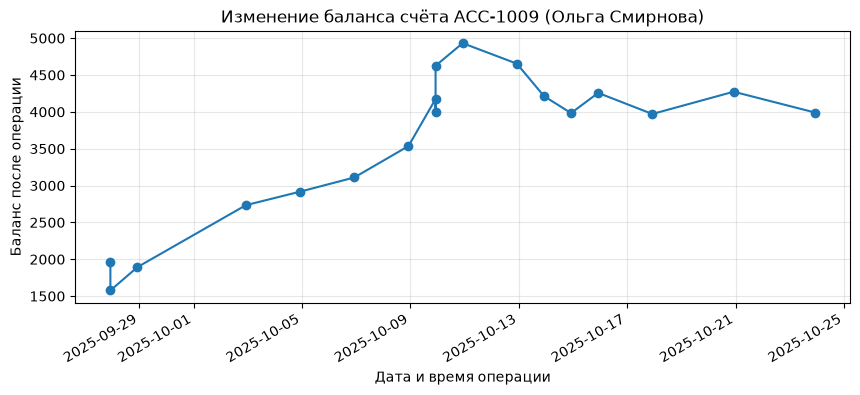

In [22]:
imported_savings.plot_balance()